In [2]:
%%capture
!pip install optuna

In [3]:
import numpy as np
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import KernelPCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.metrics import silhouette_score, accuracy_score
from sklearn.svm import LinearSVC, SVC
import optuna
optuna.logging.set_verbosity(optuna.logging.ERROR)

In [4]:
rs = 8

# Задание 1

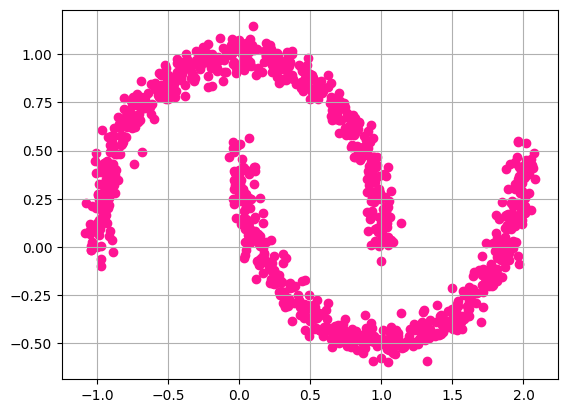

In [5]:
X, y = make_moons(n_samples=1000, noise=0.05, random_state=rs)
plt.scatter(X[:, 0], X[:, 1], c="deeppink")
plt.grid()
plt.show()

In [6]:
X.shape

(1000, 2)

# Задание 2

Отскейлим данные перед применением PCA, стандартная практика для PCA. В нашем случае мы не снижаем число компонент, но искревляем пространство, так что лучше чтобы кривилось из изначально "одинаковых" состояний

Попробуем обучить параметры kernelPCA для того чтобы найти максимально удобное пространство в котором данные будут линейно разделимы

In [7]:
%%capture
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=rs)

scaler = StandardScaler(with_mean=True, with_std=True)

X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# обучаем перевод в пространство на X_train
def objective(trial):
    kernel = trial.suggest_categorical("kernel", ["rbf", "poly", "sigmoid"])
    gamma = trial.suggest_float("gamma", 1e-3, 50, log=True)

    degree = None
    coef0 = None

    if kernel == "rbf":
        coef0 = trial.suggest_float("coef0", 1/X_train_sc.shape[1], 2)
        kpca = KernelPCA(n_components=2, kernel=kernel, gamma=gamma, coef0=coef0, random_state=rs)

    if kernel == "poly":
        degree = trial.suggest_int("degree", 3, 10)
        coef0 = trial.suggest_float("coef0", 0.0, 2.0)
        kpca = KernelPCA(n_components=2, kernel=kernel, gamma=gamma, degree=degree, coef0=coef0, random_state=rs)

    if kernel == "sigmoid":
        coef0 = trial.suggest_float("coef0", -2.0, 2.0)
        kpca = KernelPCA(n_components=2, kernel=kernel, gamma=gamma, coef0=coef0, random_state=rs)

    Z = kpca.fit_transform(X_train_sc)

    svc = LinearSVC(max_iter=5000, random_state=rs)
    svc_score = cross_val_score(svc, X_train_sc, y_train, cv=5).mean()
    sil_score = silhouette_score(X_train_sc, y_train)

    return svc_score + sil_score

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=50)
kpca_best_params = study.best_params

In [8]:
kpca = KernelPCA(n_components=2, **kpca_best_params, random_state=rs)
kpca.fit(X_train_sc)

KernelPCA(coef0=1.9967483031332467, gamma=0.005003363490404524, kernel='rbf',
          n_components=2, random_state=8)

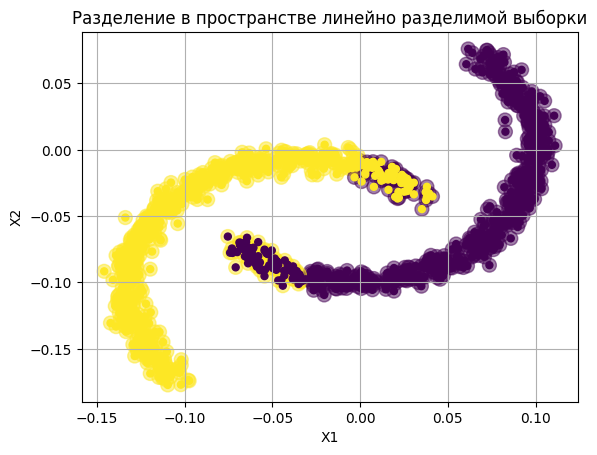

Accuracy score трейн + тест: 0.857
Accuracy score трейн: 0.8733333333333333
Accuracy score тест: 0.904


In [9]:
Z_train = kpca.transform(X_train_sc)
Z_test = kpca.transform(X_test_sc)
Z = kpca.transform(X)

svc = LinearSVC(max_iter=5000, random_state=rs)
svc.fit(Z_train, y_train)

svc_labels = svc.predict(Z)

plt.scatter(Z[:, 0], Z[:, 1], c=svc_labels, alpha=0.5, s=100)
plt.scatter(Z[:, 0], Z[:, 1], c=y, s=25)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Разделение в пространстве линейно разделимой выборки')
plt.grid(True)
plt.show()

print(f"Accuracy score трейн + тест: {accuracy_score(svc_labels, y)}")
print(f"Accuracy score трейн: {accuracy_score(svc.predict(Z_train), y_train)}")
print(f"Accuracy score тест: {accuracy_score(svc.predict(Z_test), y_test)}")

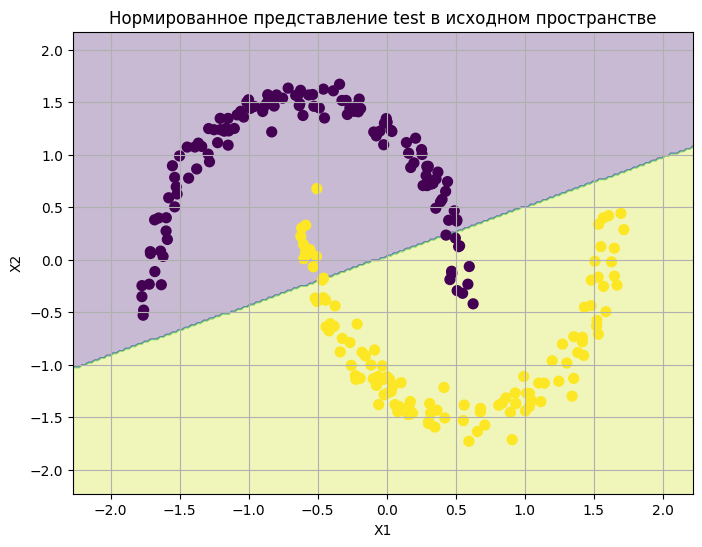

In [10]:
xx, yy = np.meshgrid(
    np.linspace(X_test_sc[:,0].min()-0.5, X_test_sc[:,0].max()+0.5, 200),
    np.linspace(X_test_sc[:,1].min()-0.5, X_test_sc[:,1].max()+0.5, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]

grid_kpca = kpca.transform(grid)

grid_labels = svc.predict(grid_kpca).reshape(xx.shape)

plt.figure(figsize=(8,6))
plt.contourf(xx, yy, grid_labels, alpha=0.3)  # фон = границы
plt.scatter(X_test_sc[:,0], X_test_sc[:,1], c=y_test, s=50)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Нормированное представление test в исходном пространстве')
plt.grid(True)
plt.show()

Получилось найти пространство, в котором выборка оказалась более менее разделимой с помощью подбора гиперпараметров с optuna.
В кратце, что произошло: взяли размеченные данные, применили kernelPCA с какими-то параметрами и попробовали разделить с помощью linearSVC

# Задание 3

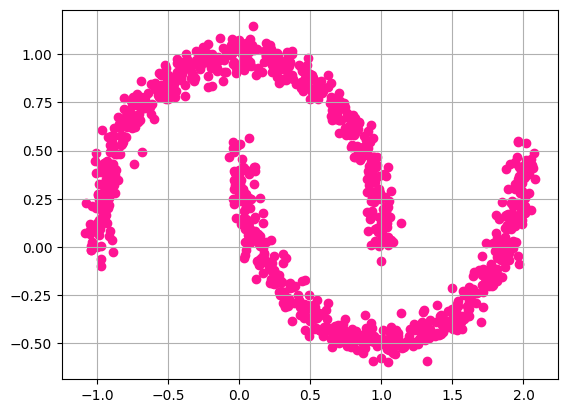

In [11]:
plt.scatter(X[:, 0], X[:, 1], c="deeppink")
plt.grid()
plt.show()

На первый взгляд выбросов нет, но попробуем реализовать их поиск

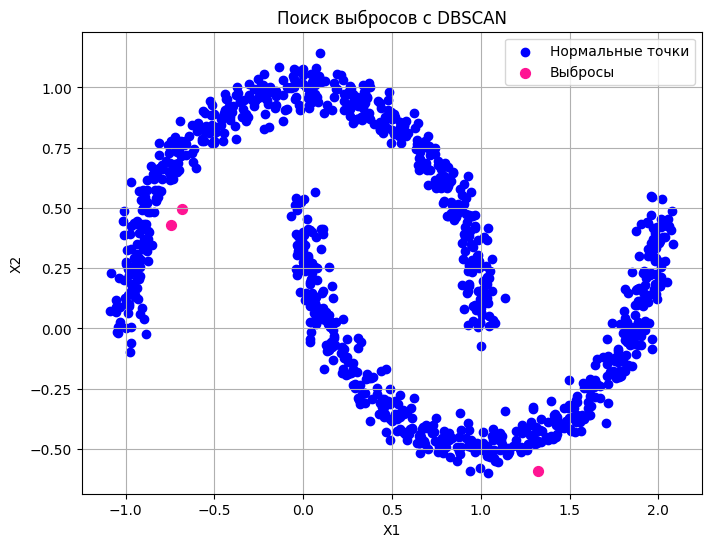

In [12]:
dbscan = DBSCAN(eps=0.095, min_samples=3)
labels = dbscan.fit_predict(X)

outliers = X[labels == -1]
inliers = X[labels != -1]

plt.figure(figsize=(8,6))
plt.scatter(inliers[:,0], inliers[:,1], c='blue', label='Нормальные точки')
plt.scatter(outliers[:,0], outliers[:,1], c='deeppink', label='Выбросы', s=50)
plt.title('Поиск выбросов с DBSCAN')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()
plt.grid(True)
plt.show()

Допустим, какие-то такие выбросы

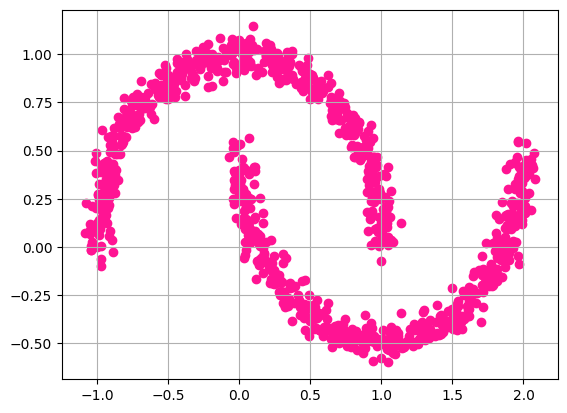

In [13]:
X_clear = X[labels != -1]
y_clear = y[labels != -1]
plt.scatter(X_clear[:, 0], X_clear[:, 1], c="deeppink")
plt.grid()
plt.show()

# Задание 4

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X_clear, y_clear, test_size=0.25, random_state=rs)

scaler = StandardScaler(with_mean=True, with_std=True)
scaler.fit(X_train)

X_train_sc = scaler.transform(X_train)
X_test_sc = scaler.transform(X_test)

kpca = KernelPCA(n_components=2, **kpca_best_params, random_state=rs)
kpca.fit(X_train_sc)

Z_train = kpca.transform(X_train_sc)
Z_test = kpca.transform(X_test_sc)

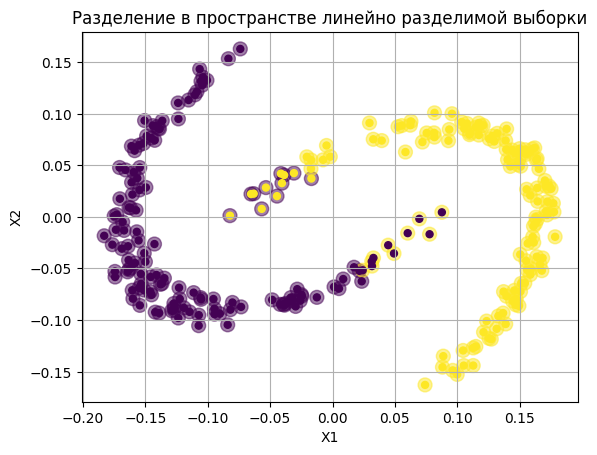

Accuracy_score: 0.916


In [15]:
svc = LinearSVC(max_iter=5000, random_state=rs)

svc.fit(Z_train, y_train)

svc_labels = svc.predict(Z_test)

svc_score = accuracy_score(y_test, svc_labels)

plt.scatter(Z_test[:, 0], Z_test[:, 1], c=svc_labels, alpha=0.5, s=100)
plt.scatter(Z_test[:, 0], Z_test[:, 1], c=y_test, s=25)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Разделение в пространстве линейно разделимой выборки')
plt.grid(True)
plt.show()

print(f"Accuracy_score: {svc_score}")

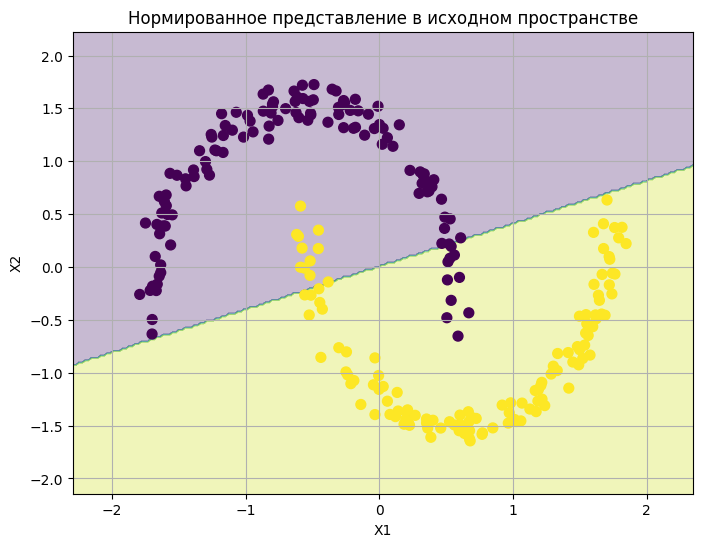

In [16]:
xx, yy = np.meshgrid(
    np.linspace(X_test_sc[:,0].min()-0.5, X_test_sc[:,0].max()+0.5, 200),
    np.linspace(X_test_sc[:,1].min()-0.5, X_test_sc[:,1].max()+0.5, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]

grid_kpca = kpca.transform(grid)

grid_labels = svc.predict(grid_kpca).reshape(xx.shape)

plt.figure(figsize=(8,6))
plt.contourf(xx, yy, grid_labels, alpha=0.3)  # фон = границы
plt.scatter(X_test_sc[:,0], X_test_sc[:,1], c=y_test, s=50)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Нормированное представление в исходном пространстве')
plt.grid(True)
plt.show()

В целом, как и раньше, в пространстве линейно разделимой выборки деление даже с linearSVC происходит неплохо, попробуем подобрать параметры для нелинейного SVC. Из соображений, что уже упростили расположение объектов в пространстве и можем попробовать сделать классификафию более гибкой.

In [17]:
%%capture
X_kpca = kpca.fit_transform(X_train_sc)

def objective(trial):
    kernel = trial.suggest_categorical("kernel", ["linear", "poly", "rbf", "sigmoid"])

    C = trial.suggest_float("C", 1e-3, 100, log=True)

    svc_params = {"kernel": kernel, "C": C, "random_state": rs}

    if kernel in ["rbf", "poly", "sigmoid"]:
        gamma = trial.suggest_float("gamma", 1e-3, 10, log=True)
        svc_params["gamma"] = gamma
    if kernel == "poly":
        degree = trial.suggest_int("degree", 2, 5)
        coef0 = trial.suggest_float("coef0", 0.0, 2.0)
        svc_params["degree"] = degree
        svc_params["coef0"] = coef0
    if kernel == "sigmoid":
        coef0 = trial.suggest_float("coef0", 0.0, 2.0)
        svc_params["coef0"] = coef0

    model = SVC(**svc_params)

    score = cross_val_score(model, X_kpca, y_train, cv=5, scoring="accuracy").mean()
    return score


study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=50)

print("Best params:")
print(study.best_params)

SVC_best_params = study.best_params

print("Best score:\t", study.best_value)

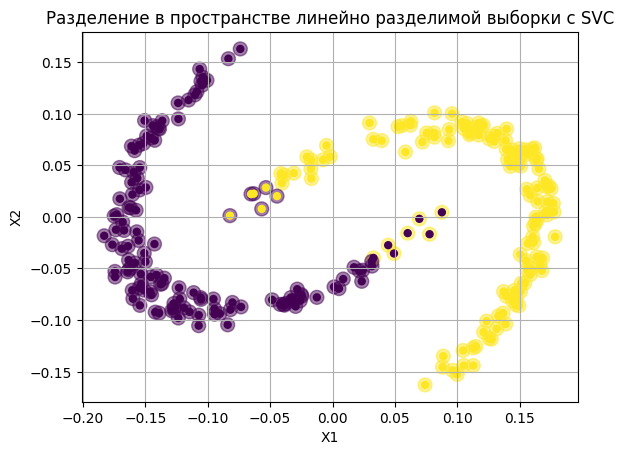

Accuracy_score: 0.948


In [18]:
svc = SVC(**SVC_best_params)

svc.fit(Z_train, y_train)

svc_labels = svc.predict(Z_test)

svc_score = accuracy_score(y_test, svc_labels)

plt.scatter(Z_test[:, 0], Z_test[:, 1], c=svc_labels, alpha=0.5, s=100)
plt.scatter(Z_test[:, 0], Z_test[:, 1], c=y_test, s=25)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Разделение в пространстве линейно разделимой выборки с SVC')
plt.grid(True)
plt.show()

print(f"Accuracy_score: {svc_score}")

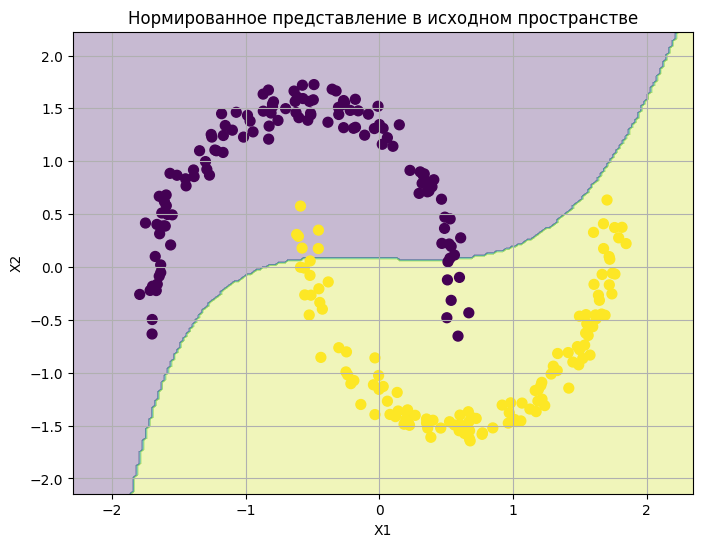

In [19]:
xx, yy = np.meshgrid(
    np.linspace(X_test_sc[:,0].min()-0.5, X_test_sc[:,0].max()+0.5, 200),
    np.linspace(X_test_sc[:,1].min()-0.5, X_test_sc[:,1].max()+0.5, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]

grid_kpca = kpca.transform(grid)

grid_labels = svc.predict(grid_kpca).reshape(xx.shape)

plt.figure(figsize=(8,6))
plt.contourf(xx, yy, grid_labels, alpha=0.3)  # фон = границы
plt.scatter(X_test_sc[:,0], X_test_sc[:,1], c=y_test, s=50)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Нормированное представление в исходном пространстве')
plt.grid(True)
plt.show()

# Задание 5



In [20]:
print(kpca_best_params)

{'kernel': 'rbf', 'gamma': 0.005003363490404524, 'coef0': 1.9967483031332467}


In [21]:
print(SVC_best_params)

{'kernel': 'rbf', 'C': 12.283253252459641, 'gamma': 4.341448028600571}


Схема эксперимента: будем брать по одному параметру и смотреть как влияет изменение каждого параметра в некоторой окрестности на score

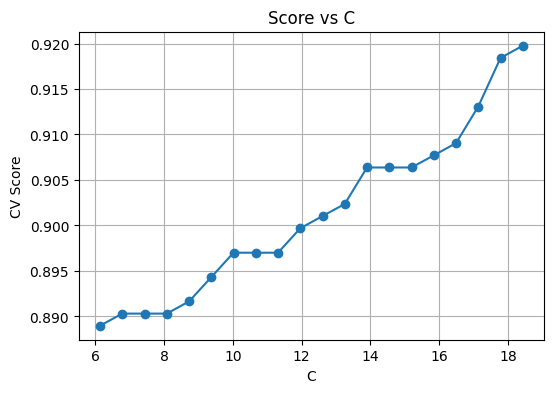

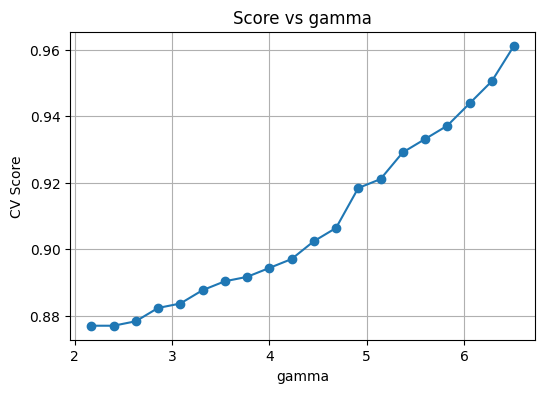

In [22]:
def plot_score_vs_param(SVC_best_params, param_name, param_vals, X_train, y_train, cv=5):
    scores = []

    for val in param_vals:
        params = SVC_best_params.copy()
        params[param_name] = val

        kernel = params.get('kernel', 'rbf')
        if kernel == 'linear':
            params.pop('gamma', None)
            params.pop('degree', None)
            params.pop('coef0', None)
        if kernel == 'rbf':
            params.pop('degree', None)
            params.pop('coef0', None)
        if kernel == 'sigmoid':
            params.pop('degree', None)

        svc = SVC(**params)
        score = cross_val_score(svc, X_train, y_train, cv=cv).mean()
        scores.append(score)

    plt.figure(figsize=(6,4))
    plt.plot(param_vals, scores, marker='o')
    plt.title(f"Score vs {param_name}")
    plt.xlabel(param_name)
    plt.ylabel("CV Score")
    plt.grid(True)
    plt.show()


param_ranges = {}
if 'C' in SVC_best_params:
    param_ranges['C'] = np.linspace(SVC_best_params['C']*0.5, SVC_best_params['C']*1.5, 20)
if 'gamma' in SVC_best_params:
    param_ranges['gamma'] = np.linspace(SVC_best_params['gamma']*0.5, SVC_best_params['gamma']*1.5, 20)
if 'degree' in SVC_best_params:
    param_ranges['degree'] = np.arange(max(2, SVC_best_params['degree']-2), SVC_best_params['degree']+3)
if 'coef0' in SVC_best_params:
    param_ranges['coef0'] = np.linspace(SVC_best_params['coef0']*0.5, SVC_best_params['coef0']*1.5, 20)


for param_name, param_vals in param_ranges.items():
    plot_score_vs_param(SVC_best_params, param_name, param_vals, Z_train, y_train)

# Задание 6

In [23]:
def data_transform(noise, kpca):
    X, y = make_moons(n_samples=1000, noise=noise, random_state=rs)

    dbscan = DBSCAN(eps=0.095, min_samples=3)
    labels = dbscan.fit_predict(X)

    X_clear = X[labels != -1]
    y_clear = y[labels != -1]

    X_train, X_test, y_train, y_test = train_test_split(X_clear, y_clear, test_size=0.25, random_state=rs)

    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc = scaler.transform(X_test)

    Z_train = kpca.transform(X_train_sc)
    Z_test = kpca.transform(X_test_sc)

    return Z_train, Z_test, y_train, y_test


def noise_sensitivity_experiment(best_params, kpca, param_name, param_vals):
    noise_levels = np.arange(0.05, 0.36, 0.05)

    results = []

    for noise in noise_levels:
        Z_train, Z_test, y_train, y_test = data_transform(noise, kpca)

        for val in param_vals:
            params = best_params.copy()
            params[param_name] = val

            kernel = params.get('kernel', 'rbf')
            if kernel == 'linear':
                params.pop('gamma', None)
                params.pop('degree', None)
                params.pop('coef0', None)
            if kernel == 'rbf':
                params.pop('degree', None)
                params.pop('coef0', None)
            if kernel == 'sigmoid':
                params.pop('degree', None)

            svc = SVC(**params)
            score = cross_val_score(svc, Z_train, y_train, cv=5).mean()
            results.append({'param': val, 'score': score, 'noise': noise})

    plt.figure(figsize=(8,6))
    for noise in noise_levels:
        subset = [r for r in results if r['noise']==noise]
        plt.scatter([r['param'] for r in subset],
                    [r['score'] for r in subset],
                    label=f'noise={noise:.2f}', alpha=0.7)

    plt.xlabel(param_name)
    plt.ylabel('CV Score')
    plt.title(f'Effect of noise on SVC score (param: {param_name})')
    plt.legend()
    plt.grid(True)
    plt.show()

In [24]:
def run_all_noise_experiments(SVC_best_params, kpca):
    param_ranges = {}
    if 'C' in SVC_best_params:
        param_ranges['C'] = np.linspace(SVC_best_params['C']*0.5, SVC_best_params['C']*1.5, 20)
    if 'gamma' in SVC_best_params:
        param_ranges['gamma'] = np.linspace(SVC_best_params['gamma']*0.5, SVC_best_params['gamma']*1.5, 20)
    if 'degree' in SVC_best_params:
        param_ranges['degree'] = np.arange(max(2, SVC_best_params['degree']-2), SVC_best_params['degree']+3)
    if 'coef0' in SVC_best_params:
        param_ranges['coef0'] = np.linspace(SVC_best_params['coef0']*0.5, SVC_best_params['coef0']*1.5, 20)

    for param_name, param_vals in param_ranges.items():
        noise_sensitivity_experiment(SVC_best_params, kpca, param_name, param_vals)

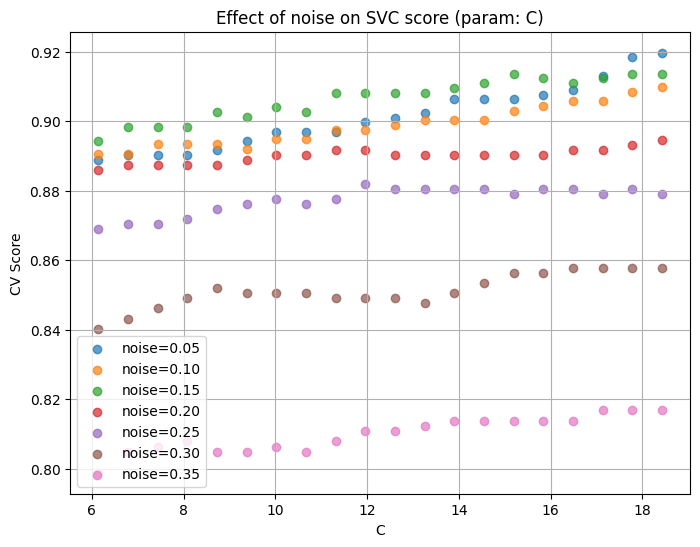

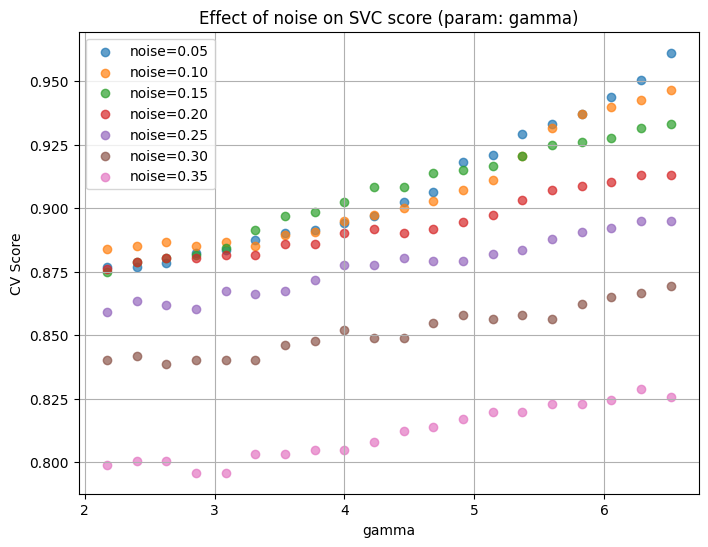

In [25]:
run_all_noise_experiments(SVC_best_params, kpca)

Можно сделать вывод, что перевод в пространство в котором малозашумленная выборка линейно разделима и дальнейшее обучение на минимальном шуме все еще остается достаточно эффективным для разделения даже более зашумленной выборки, а изменения лучших параметром в диапазоне 50% - 150% могут как влиять на скор, так и не влиять (при перезапуске всех экспериментов в случае смены ядра SVC меняется и поведение гиперпараметров).
Для poly изменения наиболее сильно влияют, для linear практически нет

Если исходно обучать более шумные данные, результат будет совпадать с обучением менее шумных данных. Комбинация "перевод в линейно разделимое" + "обучение SVM" отлично справляется

### Результат работы для данных с конкретным шумом

Accuracy_score: 0.8834080717488789


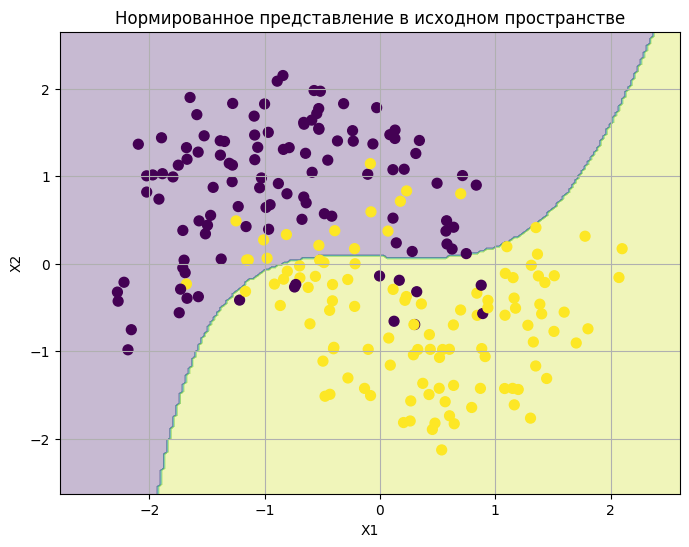

In [26]:
X, y = make_moons(n_samples=1000, noise=0.35, random_state=rs)

dbscan = DBSCAN(eps=0.095, min_samples=3)
labels = dbscan.fit_predict(X)

X_clear = X[labels != -1]
y_clear = y[labels != -1]

X_train, X_test, y_train, y_test = train_test_split(X_clear, y_clear, test_size=0.25, random_state=rs)

scaler = StandardScaler(with_mean=True, with_std=True)

X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

Z_train = kpca.transform(X_train_sc)
Z_test = kpca.transform(X_test_sc)

svc_labels = svc.predict(Z_test)
svc_score = accuracy_score(y_test, svc_labels)

print(f"Accuracy_score: {svc_score}")

xx, yy = np.meshgrid(
    np.linspace(X_test_sc[:,0].min()-0.5, X_test_sc[:,0].max()+0.5, 200),
    np.linspace(X_test_sc[:,1].min()-0.5, X_test_sc[:,1].max()+0.5, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]

grid_kpca = kpca.transform(grid)

grid_labels = svc.predict(grid_kpca).reshape(xx.shape)

plt.figure(figsize=(8,6))
plt.contourf(xx, yy, grid_labels, alpha=0.3)  # фон = границы
plt.scatter(X_test_sc[:,0], X_test_sc[:,1], c=y_test, s=50)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Нормированное представление в исходном пространстве')
plt.grid(True)
plt.show()

# Задание 7

## Оценка вычислительной сложности kernelPCA

Рассмотрим вычислительную сложность построения отображения KernelPCA при оптимальных гиперпараметрах

- n — число объектов в выборке;
- d — размерность исходного пространства признаков;
- k — число главных компонент (`n_components`).

### 1. Построение kernel-матрицы

KernelPCA основан на вычислении kernel-матрицы
размером n^2.

Для каждого элемента матрицы требуется вычисление значения ядра.  
Для наиболее распространённых ядер (RBF, polynomial) вычисление одного ядра имеет сложность O(d).

Таким образом, вычислительная сложность построения kernel-матрицы составляет: O(dn^2)

### 2. Центрирование kernel-матрицы

Данный этап включает поэлементные операции над матрицей размера n^2, поэтому его вычислительная сложность равна: O(n^2)

### 3. Спектральное разложение

Для получения главных компонент необходимо вычислить собственные значения и собственные векторы центрированной kernel-матрицы.

Полное спектральное разложение плотной матрицы имеет сложность O(n^3).  

### 4. Итоговая вычислительная сложность

Суммируя сложности всех этапов, получаем: O(n^2 * d + n^2 + n^2 * k)

Получаем: O(n^3)

Так как используется optuna с 50 итерациями и кросс-валидацией, то O(5 * 50 * n^3)


## Оценка вычислительной сложности SVC

Обучение SVC с нелинейными ядрами требует построения kernel-матрицы и решения квадратичной задачи оптимизации, поэтому в худшем случае имеет вычислительную сложность O(n^3). Использование кроссвалидации и подбора гиперпараметров с помощью Optuna увеличивает общую сложность до O(50 * 5 * n^3)



## Влияние шума на score

/tmp/ipython-input-219708699.py:43: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


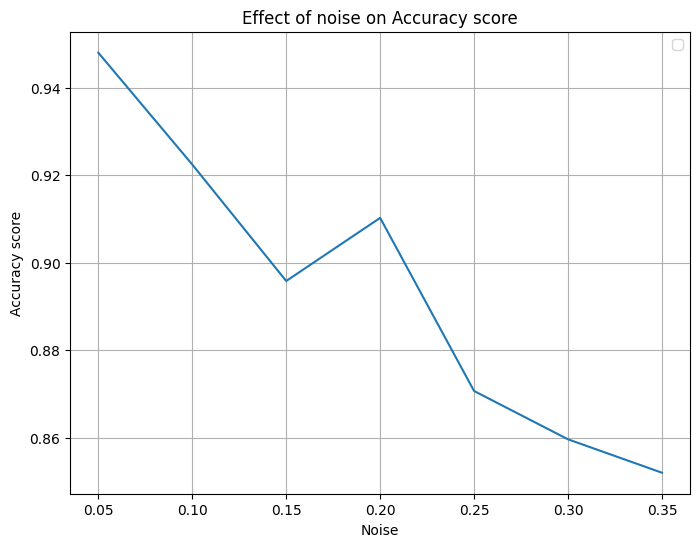

In [27]:
def data_transform(noise, kpca):
    X, y = make_moons(n_samples=1000, noise=noise, random_state=rs)

    dbscan = DBSCAN(eps=0.095, min_samples=3)
    labels = dbscan.fit_predict(X)

    X_clear = X[labels != -1]
    y_clear = y[labels != -1]

    X_train, X_test, y_train, y_test = train_test_split(X_clear, y_clear, test_size=0.25, random_state=rs)

    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc = scaler.transform(X_test)

    Z_train = kpca.transform(X_train_sc)
    Z_test = kpca.transform(X_test_sc)

    return Z_train, Z_test, y_train, y_test

noises = []
scores = []

noise_levels = np.arange(0.05, 0.36, 0.05)

for noise in noise_levels:
  Z_train, Z_test, y_train, y_test = data_transform(noise, kpca)

  svc = SVC(**SVC_best_params)
  svc.fit(Z_train, y_train)
  labels = svc.predict(Z_test)
  score = accuracy_score(labels, y_test)

  noises.append(noise)
  scores.append(score)

plt.figure(figsize=(8,6))
plt.plot(noises, scores)

plt.xlabel("Noise")
plt.ylabel('Accuracy score')
plt.title(f'Effect of noise on Accuracy score')
plt.legend()
plt.grid(True)
plt.show()

При увеличении шума усложняется разделяющая поверхность, возрастает число опорных векторов и ухудшается значение score.

Модель выдает неплохой результат даже при большом шуме. Так как каждый раз optuna возвращает новые параметры, зафиксируем одни из них для удобства

### KernelPCA
{'kernel': 'rbf', 'gamma': 0.005003363490404524, 'coef0': 1.9967483031332467}

### SVC
{'kernel': 'rbf', 'C': 12.283253252459641, 'gamma': 4.341448028600571}

In [29]:
### KernelPCA
pca_model = {'kernel': 'rbf', 'gamma': 0.005003363490404524, 'coef0': 1.9967483031332467}

### SVC
svc_model = {'kernel': 'rbf', 'C': 12.283253252459641, 'gamma': 4.341448028600571}

# Задание 8

Ниже приведены два доказательно обоснованных способа снижения вычислительной сложности обучения KernelPCA и бинарного классификатора (SVC) по сравнению с базовым вариантом, использующим полную kernel-матрицу и перебор гиперпараметров с cross-validation.


1. Замена SVC на линейный классификатор после явного отображения

Использование явного нелинейного отображения + линейный классификатор: PolynomialFeatures + LinearSVC

Идея:
- Нелинейность переносится в признаковое пространство
- Обучение выполняется линейным алгоритмом

Сложность:
- построение признаков: O(n · D)
- обучение LinearSVC: O(n · D)

Снижение сложности: O(n³) -> O(n · D)

2. Явное уменьшение константы через снижение числа запусков OPTUNA, не использовать крос-валидацию

Просто уменьшаем константу при n^3

3. Ручное изменение признакового пространства, например, тригонометрическая замена (задаем точки углом и радиусом) + linearSVC

Сложность:
- построение признаков: O(n)
- обучение LinearSVC: O(n · D)

Снижение сложности: 0(n^3) -> O(n * D)

4.


